***Tên: Bùi Ngọc Bảo Trân***

***ID: 25MS33062***

<div align="center">

# **HOMEWORK 1**

</div>

## Word2Vec Skip-gram trên tập IMDB → TensorFlow Embedding Projector

**Đề bài:** Dùng thuật toán **Skip-gram** huấn luyện word embedding trên tập dữ liệu **IMDB**, xuất vector và chiếu lên https://projector.tensorflow.org/.

**Hướng tiếp cận:**
- **Dữ liệu:** 100.000 review phim IMDB (25k train + 25k test + 50k không nhãn), tách thành câu.
- **Mô hình:** Skip-gram với **Negative Sampling** (Mikolov et al., 2013), cài đặt bằng TensorFlow / Keras.
- **Sinh cặp skip-gram, subsampling và negative sampling:** tự cài bằng NumPy (vector hoá), vì Keras 3 (TF ≥ 2.16) không còn các hàm `skipgrams` / `make_sampling_table`.
- **Subsampling** từ phổ biến dùng tần suất thật của từ: $P_{keep}(w)=\min\left(1,\sqrt{t/f(w)}+t/f(w)\right)$.
- **Negative sampling** theo phân phối unigram$^{3/4}$.
- **Hàm loss:** `BinaryCrossentropy` (sigmoid), đúng hàm mục tiêu negative sampling.

**Kết quả:** 2 file `vectors.tsv` và `metadata.tsv` để upload lên Embedding Projector.

## 1. Nhắc lại lý thuyết Skip-gram + Negative Sampling

- **Skip-gram**: cho từ trung tâm $w_t$, dự đoán các từ ngữ cảnh $w_{t+j}$ với $-c \le j \le c,\ j\neq 0$ ($c$ = `window_size`).
- Hàm mục tiêu gốc dùng softmax trên toàn bộ từ vựng → quá tốn kém. **Negative sampling** biến bài toán thành phân loại nhị phân: với mỗi cặp dương $(w, c)$, lấy thêm $k$ = `num_ns` từ "nhiễu" $c'_i \sim P_n(w) \propto U(w)^{3/4}$:

$$\log \sigma(v'_{c}\cdot v_{w}) + \sum_{i=1}^{k} \log \sigma(-v'_{c'_i}\cdot v_{w})$$

- Mô hình có 2 ma trận embedding: `target_embedding` ($v$) và `context_embedding` ($v'$). Sau khi train, ta lấy `target_embedding` làm vector của từ.

## 2. Setup

In [1]:
import io, os, re, string, tarfile, time
from collections import Counter

import numpy as np
import tensorflow as tf
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)

SEED = 42
rng = np.random.default_rng(SEED)
tf.random.set_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

TensorFlow: 2.21.0


### Siêu tham số
Có thể chỉnh ở đây. Với cấu hình mặc định, bước huấn luyện mất khoảng 20–30 phút trên CPU (nhanh hơn nếu chạy Colab có GPU).

In [2]:
VOCAB_SIZE     = 10000   # số từ trong từ vựng (kể cả '' và '[UNK]')
SEQUENCE_LEN   = 50      # độ dài tối đa của 1 câu sau khi vector hoá
WINDOW_SIZE    = 2       # số từ mỗi bên của từ trung tâm
NUM_NS         = 5       # số negative sample cho mỗi cặp dương (bài báo: 5-20 cho tập nhỏ)
SUBSAMPLE_T    = 1e-4    # ngưỡng t trong subsampling từ phổ biến
EMBEDDING_DIM  = 100
BATCH_SIZE     = 1024
EPOCHS         = 5
USE_UNSUP      = True    # True: dùng thêm 50k review không nhãn (train/unsup) -> 100k review; False -> 50k

## 3. Tải và đọc tập IMDB

Dùng bộ **Large Movie Review Dataset** (Maas et al., 2011) gồm 25k review train + 25k review test + 50k review không nhãn (`train/unsup`).
Word2Vec là học **không giám sát** nên ta không cần nhãn pos/neg, chỉ cần văn bản.

File `.tar.gz` được đọc trực tiếp, không cần giải nén ra đĩa.

In [3]:
url = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"
tar_path = tf.keras.utils.get_file("aclImdb_v1.tar.gz", url)

folders = "pos|neg|unsup" if USE_UNSUP else "pos|neg"
pattern = re.compile(r"^aclImdb/(train|test)/(%s)/[^/]+\.txt$" % folders)
reviews = []
t0 = time.time()
with tarfile.open(tar_path, "r:gz") as tar:
    for member in tar:
        if member.isfile() and pattern.match(member.name):
            reviews.append(tar.extractfile(member).read().decode("utf-8"))
print(f"Đọc {len(reviews):,} review trong {time.time()-t0:.1f}s")
print("\nVí dụ:\n", reviews[0][:500])

84125825/84125825 ━━━━━━━━━━━━━━━━━━━━ 142s 2us/step
Đọc 100,000 review trong 1.7s

Ví dụ:
 I love sci-fi and am willing to put up with a lot. Sci-fi movies/TV are usually underfunded, under-appreciated and misunderstood. I tried to like this, I really did, but it is to good TV sci-fi as Babylon 5 is to Star Trek (the original). Silly prosthetics, cheap cardboard sets, stilted dialogues, CG that doesn't match the background, and painfully one-dimensional characters cannot be overcome with a 'sci-fi' setting. (I'm sure there are those of you out there who think Babylon 5 is good sci-fi 


## 4. Tiền xử lý văn bản

Review IMDB có thẻ HTML `<br />`, dấu câu, chữ hoa... Các bước:
1. Bỏ thẻ HTML, chuyển chữ thường.
2. **Tách review thành câu** (theo `. ! ?`) — để cửa sổ skip-gram không vượt qua ranh giới câu và tránh phải cắt cụt review dài.
3. Bỏ dấu câu (giữ dấu nháy đơn trong từ như `don't`, `isn't`).

In [4]:
HTML_RE   = re.compile(r"<[^>]+>")
SENT_RE   = re.compile(r"[.!?;]+")
PUNCT_RE  = re.compile(r"[^a-z0-9' ]+")
QUOTE_RE  = re.compile(r"(?<![a-z])'|'(?![a-z])")   # bỏ ' không nằm giữa 2 chữ cái
SPACE_RE  = re.compile(r"\s+")

def review_to_sentences(text):
    text = HTML_RE.sub(" ", text).lower()
    out = []
    for s in SENT_RE.split(text):
        s = PUNCT_RE.sub(" ", s)
        s = QUOTE_RE.sub(" ", s)
        s = SPACE_RE.sub(" ", s).strip()
        if len(s.split()) >= 2:          # câu 1 từ không tạo được cặp skip-gram
            out.append(s)
    return out

sentences = [s for r in reviews for s in review_to_sentences(r)]
print(f"{len(sentences):,} câu, {sum(len(s.split()) for s in sentences):,} token")
for s in sentences[:5]:
    print(" -", s)

1,313,322 câu, 23,239,819 token
 - i love sci fi and am willing to put up with a lot
 - sci fi movies tv are usually underfunded under appreciated and misunderstood
 - i tried to like this i really did but it is to good tv sci fi as babylon 5 is to star trek the original
 - silly prosthetics cheap cardboard sets stilted dialogues cg that doesn't match the background and painfully one dimensional characters cannot be overcome with a sci fi setting
 - i'm sure there are those of you out there who think babylon 5 is good sci fi tv


## 5. Vector hoá bằng `TextVectorization`

Dùng `TextVectorization` để xây từ vựng (sắp theo tần suất giảm dần) và ánh xạ câu → dãy số nguyên.
Index `0` = padding, `1` = `[UNK]` (từ ngoài từ vựng).

In [5]:
vectorize_layer = layers.TextVectorization(
    standardize=None,            # đã chuẩn hoá ở bước trên
    max_tokens=VOCAB_SIZE,
    output_mode="int",
    output_sequence_length=SEQUENCE_LEN)

text_ds = tf.data.Dataset.from_tensor_slices(sentences)
vectorize_layer.adapt(text_ds.batch(4096))

inverse_vocab = [str(w) for w in vectorize_layer.get_vocabulary()]
vocab_size = len(inverse_vocab)
print("vocab_size:", vocab_size)
print(inverse_vocab[:30])

vocab_size: 10000
['', '[UNK]', 'the', 'and', 'a', 'of', 'to', 'is', 'in', 'it', 'i', 'this', 'that', 'was', 'as', 'with', 'for', 'movie', 'but', 'film', 'on', 'you', 'not', 'are', 'his', 'have', 'be', 'one', 'he', 'all']


In [6]:
sequences = np.concatenate(
    [b.numpy() for b in text_ds.batch(8192).map(vectorize_layer, num_parallel_calls=AUTOTUNE)],
    axis=0).astype(np.int32)
print("sequences.shape:", sequences.shape)
for seq in sequences[:3]:
    print(seq[:15], "=>", [inverse_vocab[i] for i in seq if i != 0])

sequences.shape: (1313322, 50)
[  10  112  838  840    3  241 1706    6  281   53   15    4  169    0
    0] => ['i', 'love', 'sci', 'fi', 'and', 'am', 'willing', 'to', 'put', 'up', 'with', 'a', 'lot']
[ 838  840   98  245   23  625    1  451 2646    3 6653    0    0    0
    0] => ['sci', 'fi', 'movies', 'tv', 'are', 'usually', '[UNK]', 'under', 'appreciated', 'and', 'misunderstood']
[ 10 781   6  37  11  10  65 118  18   9   7   6  49 245 838] => ['i', 'tried', 'to', 'like', 'this', 'i', 'really', 'did', 'but', 'it', 'is', 'to', 'good', 'tv', 'sci', 'fi', 'as', '[UNK]', '5', 'is', 'to', 'star', 'trek', 'the', 'original']


## 6. Sinh dữ liệu huấn luyện Skip-gram

### 6.1 Subsampling từ phổ biến
Các từ như *the, a, and, of* xuất hiện quá nhiều nhưng ít mang thông tin. Theo Mikolov et al. (2013), mỗi lần xuất hiện của từ $w$ được **giữ lại** với xác suất

$$P_{keep}(w)=\min\left(1,\ \sqrt{\tfrac{t}{f(w)}}+\tfrac{t}{f(w)}\right)$$

với $f(w)$ là tần suất tương đối của $w$ trong corpus. Ta cũng bỏ token padding (`0`) và `[UNK]` (`1`).

In [7]:
counts = np.bincount(sequences.ravel(), minlength=vocab_size).astype(np.float64)
counts[:2] = 0                                   # không tính pad và [UNK]
freq = counts / counts.sum()
with np.errstate(divide="ignore"):
    keep_prob = np.minimum(1.0, np.sqrt(SUBSAMPLE_T / freq) + SUBSAMPLE_T / freq)
keep_prob[:2] = 0.0

for w in ["the", "and", "movie", "film", "good", "terrible", "hitchcock"]:
    i = inverse_vocab.index(w) if w in inverse_vocab else None
    if i is not None:
        print(f"{w:>10s}: freq={freq[i]:.5f}  P_keep={keep_prob[i]:.3f}")

       the: freq=0.06154  P_keep=0.042
       and: freq=0.02985  P_keep=0.061
     movie: freq=0.00802  P_keep=0.124
      film: freq=0.00719  P_keep=0.132
      good: freq=0.00272  P_keep=0.228
  terrible: freq=0.00030  P_keep=0.910
 hitchcock: freq=0.00005  P_keep=1.000


### 6.2 Sinh cặp (target, context) dương
Hàm `skipgram_pairs` được cài bằng NumPy, vector hoá hoàn toàn:
nối mọi câu thành một mảng dài kèm `sentence_id`, rồi với mỗi độ lệch $d \in \{-c..-1, 1..c\}$ lấy cặp `(tokens[i], tokens[i+d])` khi hai vị trí cùng câu.

Minh hoạ với câu *"The wide road shimmered in the hot sun"*, `window_size=2`:

In [8]:
def skipgram_pairs(sequences, window_size, keep_prob=None, rng=None):
    # Trả về mảng (N, 2) các cặp (target, context) dương.
    seq_ids = np.repeat(np.arange(len(sequences)), sequences.shape[1])
    toks = sequences.ravel()
    mask = toks > 1                                   # bỏ pad và [UNK]
    if keep_prob is not None:                         # subsampling
        mask &= rng.random(toks.shape[0]) < keep_prob[toks]
    toks, seq_ids = toks[mask], seq_ids[mask]

    pairs = []
    for d in range(1, window_size + 1):
        same = seq_ids[:-d] == seq_ids[d:]            # cùng một câu
        a, b = toks[:-d][same], toks[d:][same]
        pairs.append(np.stack([a, b], 1))             # context ở bên phải
        pairs.append(np.stack([b, a], 1))             # context ở bên trái
    return np.concatenate(pairs).astype(np.int32)

# Minh hoạ trên một câu ví dụ
demo_vocab = ["", "[UNK]", "the", "wide", "road", "shimmered", "in", "hot", "sun"]
demo_seq = np.array([[2, 3, 4, 5, 6, 2, 7, 8, 0, 0]])
demo_pairs = skipgram_pairs(demo_seq, window_size=2)
print(len(demo_pairs), "cặp dương, ví dụ:")
for t, c in demo_pairs[:6]:
    print(f"  ({demo_vocab[t]}, {demo_vocab[c]})")

26 cặp dương, ví dụ:
  (the, wide)
  (wide, road)
  (road, shimmered)
  (shimmered, in)
  (in, the)
  (the, hot)


In [9]:
positive_pairs = skipgram_pairs(sequences, WINDOW_SIZE, keep_prob, rng)
rng.shuffle(positive_pairs)
print(f"{len(positive_pairs):,} cặp skip-gram dương")
for t, c in positive_pairs[:8]:
    print(f"  ({inverse_vocab[t]}, {inverse_vocab[c]})")

32,805,392 cặp skip-gram dương
  (pass, otherwise)
  (crazy, call)
  (movie, type)
  (it's, late)
  (comedy, entertaining)
  (alone, seven)
  (made, split)
  (scientific, deeper)


### 6.3 Negative sampling
Với mỗi cặp dương, lấy `NUM_NS` từ ngữ cảnh "giả" theo phân phối nhiễu $P_n(w) \propto \text{count}(w)^{3/4}$ (Mikolov et al., 2013).
Việc lấy mẫu được thực hiện một lần (vector hoá) cho toàn bộ dữ liệu thay vì từng cặp, nên rất nhanh dù có hàng chục triệu cặp.
Negative trùng với context dương sẽ được lấy mẫu lại.

Mỗi mẫu huấn luyện: `target` (1 số), `context` (1 + NUM_NS số), `label` = `[1, 0, 0, ..., 0]`.

In [10]:
noise_dist = counts ** 0.75
noise_dist /= noise_dist.sum()

def sample_negatives(contexts_pos, num_ns, rng):
    neg = rng.choice(vocab_size, size=(len(contexts_pos), num_ns), p=noise_dist).astype(np.int32)
    clash = neg == contexts_pos[:, None]
    while clash.any():                                 # lấy lại các negative trùng positive
        neg[clash] = rng.choice(vocab_size, size=clash.sum(), p=noise_dist)
        clash = neg == contexts_pos[:, None]
    return neg

targets  = positive_pairs[:, 0]
negs     = sample_negatives(positive_pairs[:, 1], NUM_NS, rng)
contexts = np.concatenate([positive_pairs[:, 1:2], negs], axis=1)
labels   = np.zeros_like(contexts, dtype=np.float32); labels[:, 0] = 1.0

print("targets :", targets.shape)
print("contexts:", contexts.shape)
print("labels  :", labels.shape)
i = 0
print(f"\nVí dụ: target='{inverse_vocab[targets[i]]}'")
print("  context:", [inverse_vocab[c] for c in contexts[i]])
print("  label  :", labels[i])

targets : (32805392,)
contexts: (32805392, 6)
labels  : (32805392, 6)

Ví dụ: target='pass'
  context: ['otherwise', 'that', 'role', "isn't", 'these', 'to']
  label  : [1. 0. 0. 0. 0. 0.]


### 6.4 Tạo `tf.data.Dataset`

In [11]:
dataset = tf.data.Dataset.from_tensor_slices(((targets, contexts), labels))
dataset = dataset.shuffle(100_000, seed=SEED).batch(BATCH_SIZE, drop_remainder=True).prefetch(AUTOTUNE)
print(dataset.element_spec)

((TensorSpec(shape=(1024,), dtype=tf.int32, name=None), TensorSpec(shape=(1024, 6), dtype=tf.int32, name=None)), TensorSpec(shape=(1024, 6), dtype=tf.float32, name=None))


## 7. Mô hình Word2Vec (Skip-gram)

Mô hình gồm 2 lớp `Embedding` (target và context). Logit của mỗi cặp là tích vô hướng giữa vector target và từng vector context.
Hàm loss là **sigmoid + binary cross-entropy**, đúng như hàm mục tiêu negative sampling ở mục 1.

In [12]:
class Word2Vec(tf.keras.Model):
    def __init__(self, vocab_size, embedding_dim):
        super().__init__()
        self.target_embedding = layers.Embedding(vocab_size, embedding_dim, name="w2v_embedding")
        self.context_embedding = layers.Embedding(vocab_size, embedding_dim, name="context_embedding")

    def call(self, pair):
        target, context = pair
        if len(target.shape) == 2:
            target = tf.squeeze(target, axis=1)
        word_emb = self.target_embedding(target)            # (batch, embed)
        context_emb = self.context_embedding(context)       # (batch, 1+num_ns, embed)
        return tf.einsum("be,bce->bc", word_emb, context_emb)   # logits (batch, 1+num_ns)

word2vec = Word2Vec(vocab_size, EMBEDDING_DIM)
word2vec.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=[tf.keras.metrics.BinaryAccuracy(threshold=0.0, name="accuracy")])

In [13]:
history = word2vec.fit(dataset, epochs=EPOCHS, verbose=2)   # verbose=2: mỗi epoch in 1 dòng

Epoch 1/5


/opt/miniconda3/envs/msa/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


32036/32036 - 130s - 4ms/step - accuracy: 0.8400 - loss: 0.4127
Epoch 2/5
32036/32036 - 123s - 4ms/step - accuracy: 0.8456 - loss: 0.3988
Epoch 3/5
32036/32036 - 126s - 4ms/step - accuracy: 0.8462 - loss: 0.3970
Epoch 4/5
32036/32036 - 129s - 4ms/step - accuracy: 0.8463 - loss: 0.3964
Epoch 5/5
32036/32036 - 130s - 4ms/step - accuracy: 0.8464 - loss: 0.3961


## 8. Kiểm tra nhanh chất lượng embedding

Tìm các từ gần nhất theo **cosine similarity**. Nếu học tốt, các từ cùng ngữ nghĩa (vd. *good – great – decent*, *bad – awful – terrible*) sẽ nằm gần nhau.

In [14]:
weights = word2vec.target_embedding.get_weights()[0]
norm_w = weights / (np.linalg.norm(weights, axis=1, keepdims=True) + 1e-9)
word2idx = {w: i for i, w in enumerate(inverse_vocab)}

def nearest(word, k=8):
    if word not in word2idx:
        return f"'{word}' không có trong từ vựng"
    with np.errstate(all="ignore"):   # NumPy 2.x + Accelerate (macOS) báo warning giả ở matmul; kết quả vẫn đúng
        sims = norm_w @ norm_w[word2idx[word]]
    sims[:2] = -1
    best = np.argsort(-sims)[1:k+1]
    return ", ".join(f"{inverse_vocab[j]} ({sims[j]:.2f})" for j in best)

for w in ["good", "bad", "excellent", "boring", "funny", "scary", "actor", "director", "music", "love"]:
    print(f"{w:>10s} → {nearest(w)}")

      good → decent (0.69), bad (0.67), great (0.66), nice (0.65), fine (0.62), terrific (0.57), excellent (0.52), alright (0.51)
       bad → terrible (0.74), horrible (0.71), good (0.67), lousy (0.65), awful (0.64), crappy (0.64), dumb (0.63), lame (0.61)
 excellent → superb (0.83), outstanding (0.82), terrific (0.79), fantastic (0.79), fine (0.75), wonderful (0.74), brilliant (0.73), marvelous (0.72)
    boring → dull (0.84), tedious (0.81), uninteresting (0.74), pointless (0.72), predictable (0.70), unfunny (0.64), slow (0.63), stupid (0.63)
     funny → hilarious (0.74), amusing (0.69), humorous (0.69), scary (0.62), witty (0.60), clever (0.59), entertaining (0.58), unintentionally (0.57)
     scary → creepy (0.69), frightening (0.64), funny (0.62), suspenseful (0.59), gory (0.59), thrilling (0.58), shocking (0.55), spooky (0.55)
     actor → actress (0.71), role (0.65), performer (0.64), actors (0.62), performance (0.61), comedian (0.55), crowe (0.54), singer (0.52)
  director → 

## 9. Xuất vector cho Embedding Projector

- `vectors.tsv`: mỗi dòng là một vector (các số cách nhau bởi tab).
- `metadata.tsv`: mỗi dòng là từ tương ứng.

Bỏ index `0` (padding) và `1` (`[UNK]`).

In [15]:
with io.open("vectors.tsv", "w", encoding="utf-8") as out_v, \
     io.open("metadata.tsv", "w", encoding="utf-8") as out_m:
    for index, word in enumerate(inverse_vocab):
        if index < 2:
            continue
        out_v.write("\t".join(f"{x:.6f}" for x in weights[index]) + "\n")
        out_m.write(word + "\n")

print("Đã ghi:", os.path.abspath("vectors.tsv"), f"({os.path.getsize('vectors.tsv')/1e6:.1f} MB)")
print("Đã ghi:", os.path.abspath("metadata.tsv"))

Đã ghi: /Users/bngbtran/BNGBTRAN/NLP501/Exercise/Exercise 1/vectors.tsv (9.5 MB)
Đã ghi: /Users/bngbtran/BNGBTRAN/NLP501/Exercise/Exercise 1/metadata.tsv


In [16]:
# Nếu chạy trên Google Colab thì tự động tải 2 file về máy
try:
    from google.colab import files
    files.download("vectors.tsv")
    files.download("metadata.tsv")
except Exception:
    pass

## 10. Kết quả chiếu lên Embedding Projector

Hai file `vectors.tsv` (9.998 từ × 100 chiều) và `metadata.tsv` được tải lên https://projector.tensorflow.org/. Phép giảm chiều dùng **PCA** (3 thành phần chính, bật *Sphereize data*).

**Hình 1 – Toàn bộ 9.998 vector từ sau khi chiếu PCA 3 chiều.**
3 thành phần chính chỉ giải thích **11,1%** phương sai. Điều này hợp lý với embedding 100 chiều: thông tin ngữ nghĩa phân bố trên nhiều chiều, nên đám mây điểm tổng thể không tách cụm rõ:

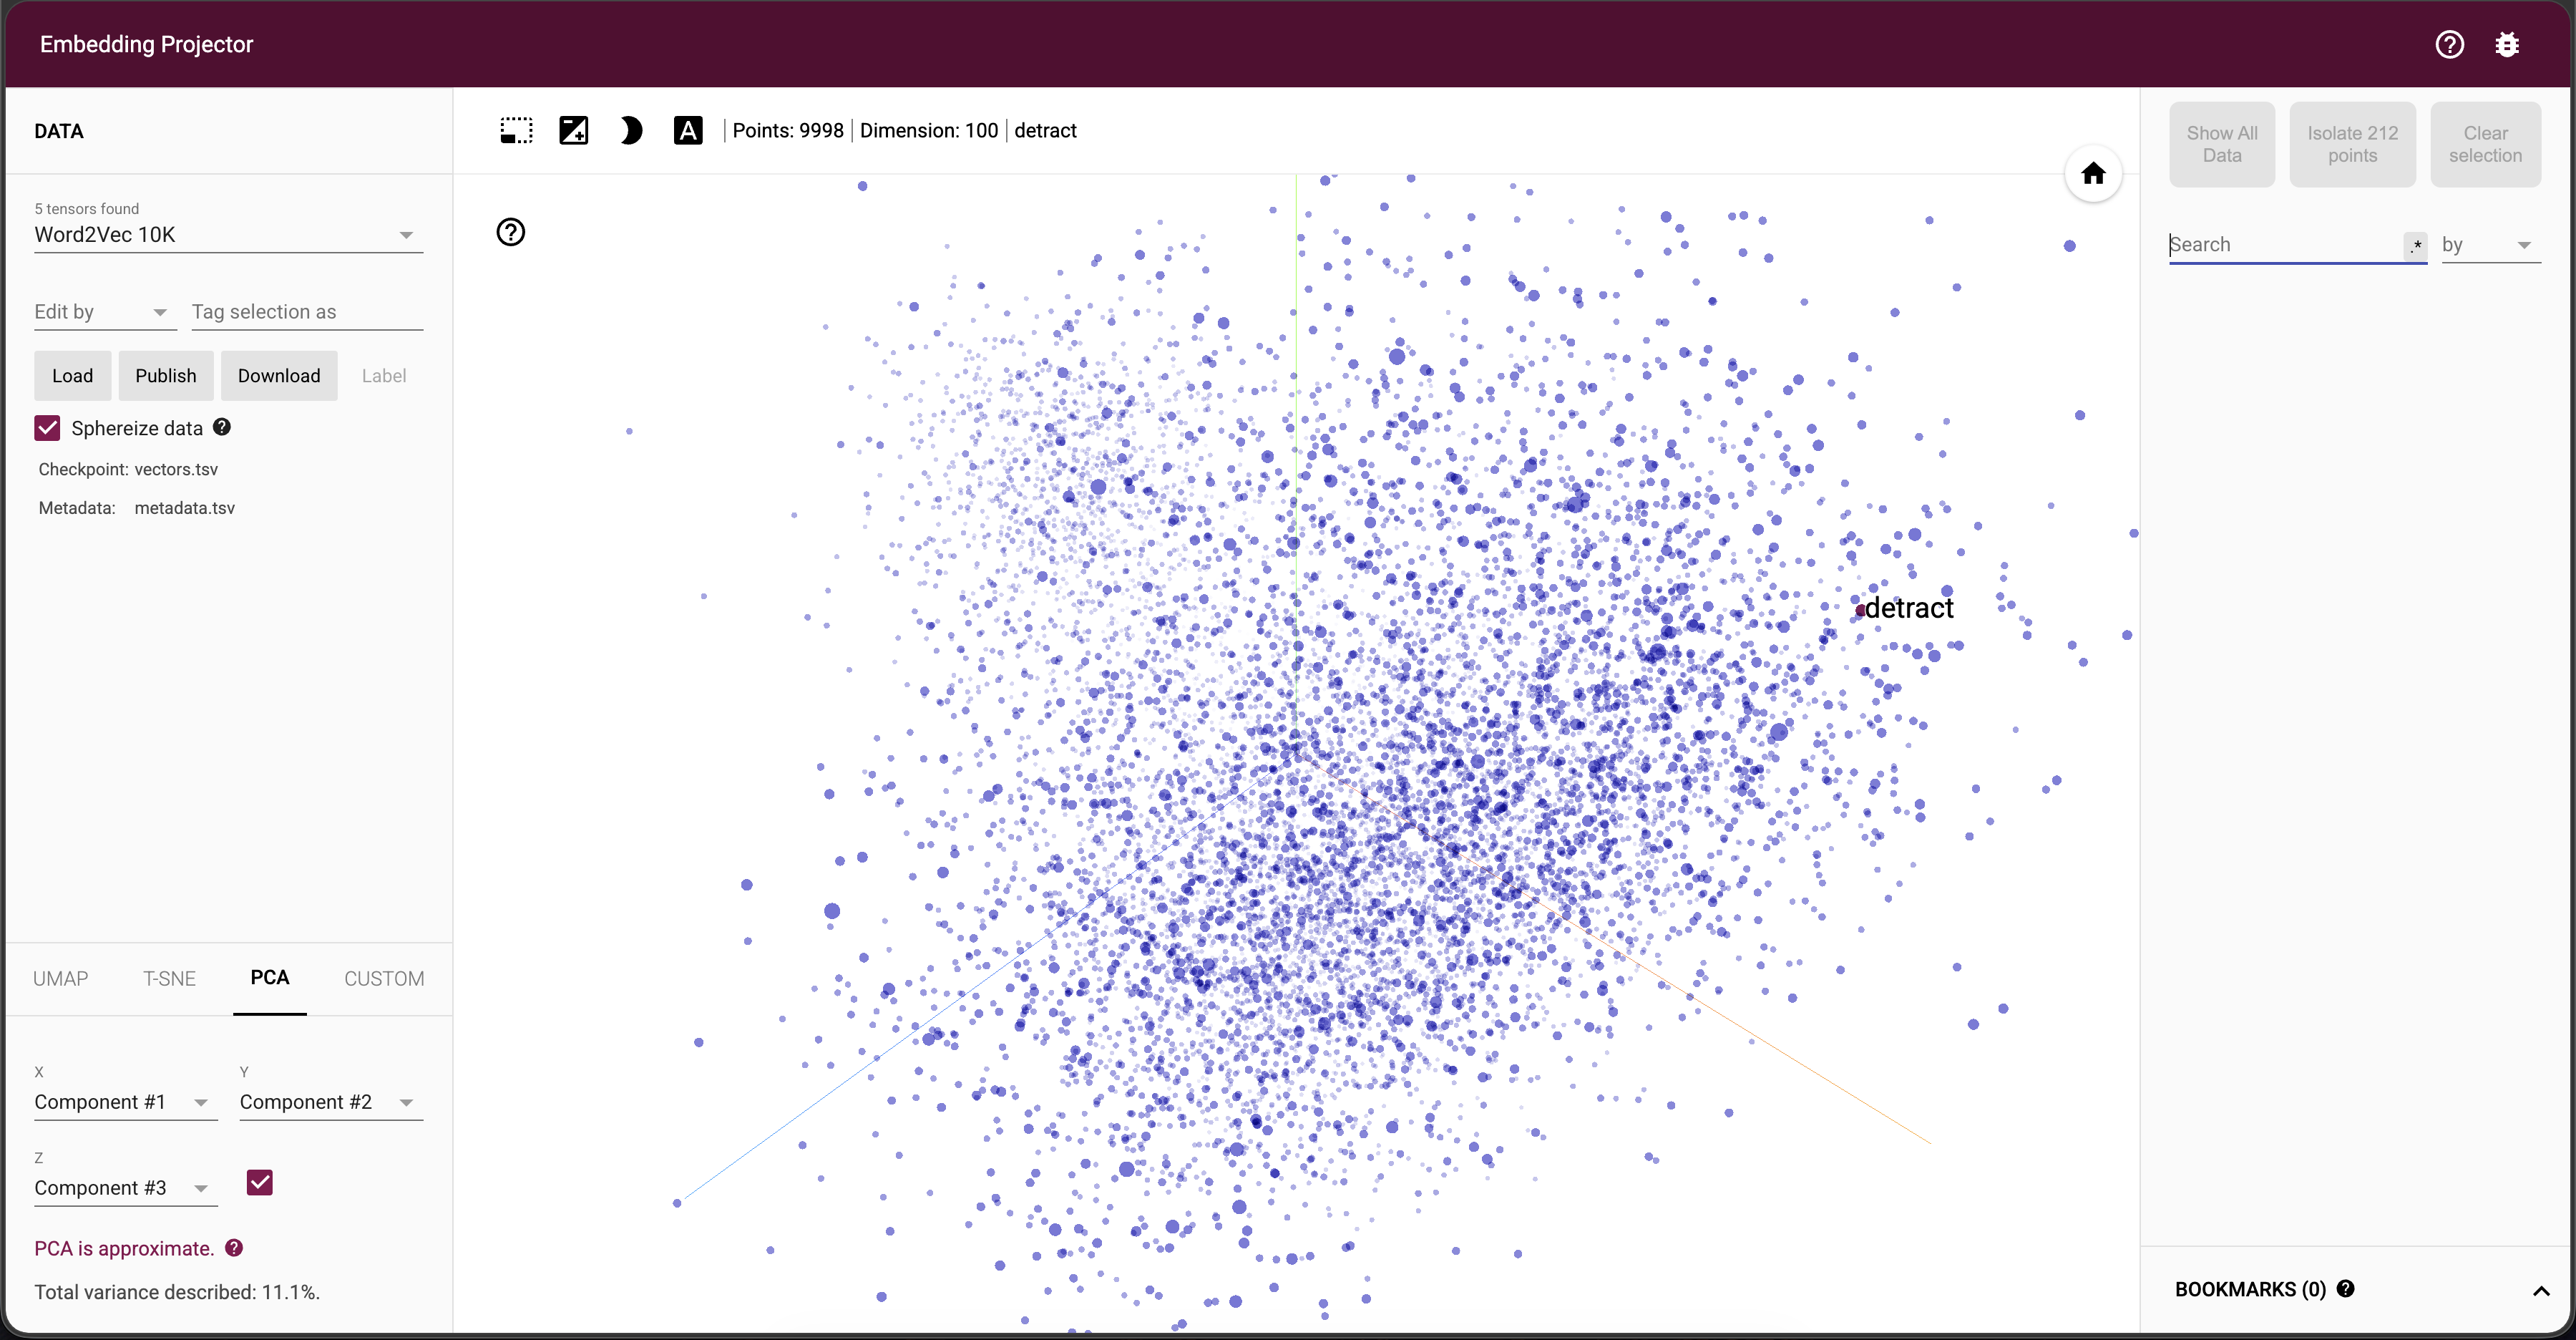

**Hình 2 – Tìm kiếm từ `music` (5 kết quả: music, musical, musicals, musician, musicians).**
Các từ *music*, *musical*, *musicals* nằm gần nhau ở cùng một vùng. *musician* và *musicians* lệch xa hơn: chúng chỉ người (danh từ chỉ nghề) nên xuất hiện trong ngữ cảnh khác (cùng ngữ cảnh với *actor*, *director*...):

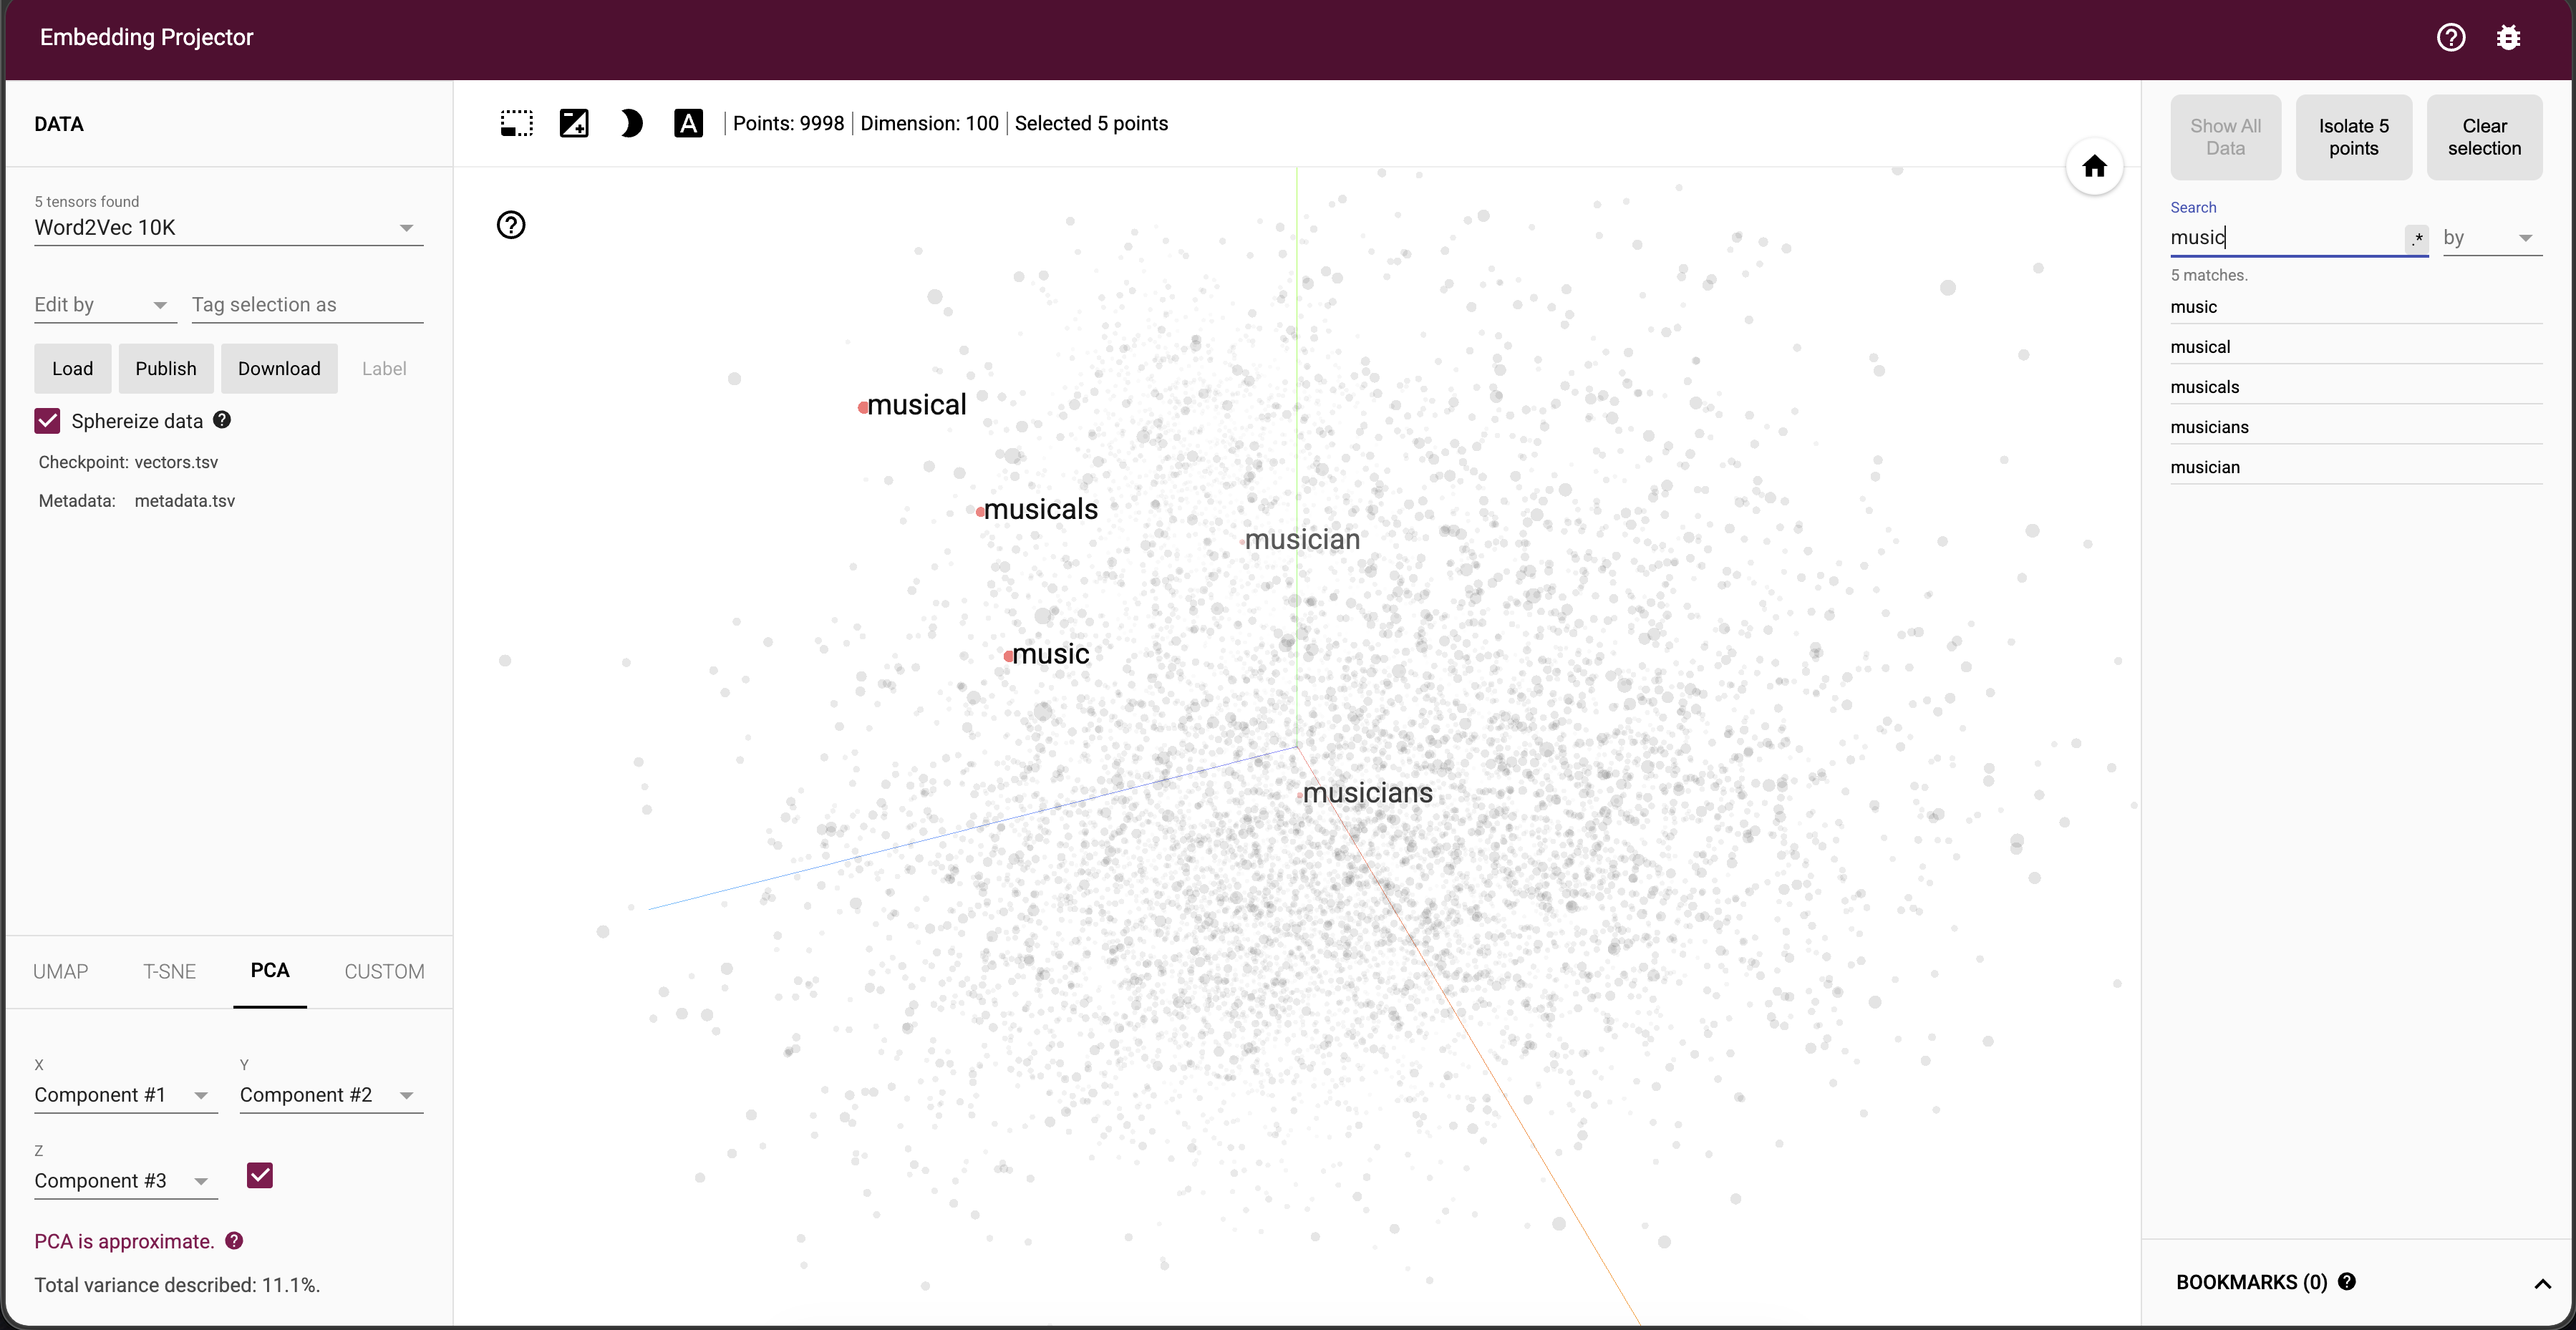

## 11. Nhận xét kết quả

- **Dữ liệu:** 100.000 review → 1,31 triệu câu, 23,2 triệu token. Từ vựng 10.000 từ. Sau subsampling (`t = 1e-4`) thu được khoảng **32,8 triệu** cặp skip-gram dương, mỗi cặp kèm 5 negative.
- **Huấn luyện:** 5 epoch. Loss giảm từ 0,413 xuống 0,396, accuracy khoảng 0,846. Loss gần như hội tụ sau epoch 2–3.
- **Chất lượng embedding:** các từ gần nhất (cosine) cho thấy mô hình học được ngữ nghĩa:
  - *boring* → dull, tedious, uninteresting
  - *excellent* → outstanding, superb, fantastic
  - *director* → writer, screenwriter, producer
  - *music* → soundtrack, score
- **Từ trái nghĩa nằm gần nhau:** *good* và *bad* có vector khá gần nhau. Đây là đặc điểm đã biết của Word2Vec: mô hình học theo **ngữ cảnh xuất hiện**, mà từ trái nghĩa thường xuất hiện trong ngữ cảnh giống nhau (*"the movie was good/bad"*).
- **Trên Embedding Projector (PCA):** đám mây điểm tổng thể không tách cụm rõ (3 thành phần chính chỉ giữ 11,1% phương sai). Tuy vậy, các từ cùng nghĩa/cùng gốc như *music – musical – musicals* vẫn nằm gần nhau (Hình 2).